In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1. Load the cleaned dataset
df_house = pd.read_csv("cleandataset.csv")

# 2. Keep the latest sale for duplicate houses (consistent with H1 & H2)
df_unique = df_house.sort_values("date").drop_duplicates(subset="id", keep="last").copy()

# 3. Quick check of shape and columns
print(f"Total unique properties: {len(df_unique):,}")

Total unique properties: 21,373


In [2]:
# 1. Convert date column to datetime format
df_unique['date'] = pd.to_datetime(df_unique['date'])

# 2. Extract sale month (1 = Jan, 12 = Dec)
df_unique['sale_month'] = df_unique['date'].dt.month

# 3. Calculate median price per month across the King County market
monthly_summary = (
    df_unique.groupby('sale_month')['price']
    .median()
    .reset_index()
)

# 4. Display the table summary
display(monthly_summary)

,sale_month,price
0,1,437000.0
1,2,426045.0
2,3,450000.0
3,4,475750.0
4,5,463000.0
5,6,465000.0
6,7,468000.0
7,8,445000.0
8,9,450000.0
9,10,449000.0


In [3]:
# 1. Define seasonal month groups
winter_months = [12, 1, 2]     # December, January, February
summer_months = [5, 6, 7]      # May, June, July

# 2. Compute median prices for winter and peak summer
winter_median = df_unique[df_unique['sale_month'].isin(winter_months)]['price'].median()
summer_median = df_unique[df_unique['sale_month'].isin(summer_months)]['price'].median()

# 3. Calculate percentage difference (winter savings)
price_diff_pct = ((summer_median - winter_median) / summer_median) * 100

# 4. Print results for Slide 07
print(f"Winter median price: ${winter_median:,.0f}")
print(f"May to July median price: ${summer_median:,.0f}")
print(f"Price Difference: {price_diff_pct:.1f}% (Expected: 5-8%)")

Winter median price: $430,000
May to July median price: $465,000
Price Difference: 7.5% (Expected: 5-8%)


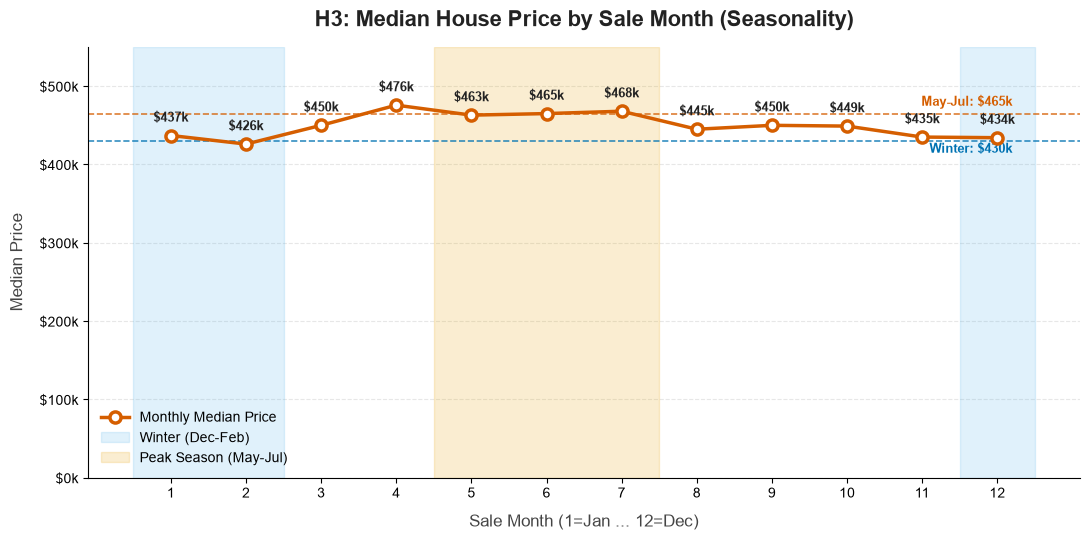

In [4]:
# 1. Set font family consistent with project standard
plt.rcParams["font.family"] = "Arial"

fig, ax = plt.subplots(figsize=(11, 5.5))

# 2. Plot monthly median price trend line
ax.plot(
    monthly_summary['sale_month'], 
    monthly_summary['price'], 
    color='#D55E00', 
    marker='o', 
    markersize=8, 
    markerfacecolor='white', 
    markeredgewidth=2.5, 
    linewidth=2.5, 
    label='Monthly Median Price',
    zorder=4
)

# 3. Add text annotations for each month in $k
for _, row in monthly_summary.iterrows():
    ax.annotate(
        f"${row['price']/1000:.0f}k", 
        (row['sale_month'], row['price']), 
        textcoords="offset points", 
        xytext=(0, 10), 
        ha='center', 
        fontsize=9.5, 
        fontweight='bold', 
        color='#222222'
    )

# 4. Highlight winter and summer peak zones
ax.axvspan(11.5, 12.5, color='#56B4E9', alpha=0.18, label='Winter (Dec-Feb)')
ax.axvspan(0.5, 2.5, color='#56B4E9', alpha=0.18)
ax.axvspan(4.5, 7.5, color='#E69F00', alpha=0.18, label='Peak Season (May-Jul)')

# 5. Add horizontal reference lines for seasonal medians
ax.axhline(winter_median, color='#0072B2', linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(12.2, winter_median - 15_000, f"Winter: ${winter_median/1000:.0f}k", 
        color='#0072B2', fontweight='bold', fontsize=9.5, ha='right')

ax.axhline(summer_median, color='#D55E00', linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(12.2, summer_median + 10_000, f"May-Jul: ${summer_median/1000:.0f}k", 
        color='#D55E00', fontweight='bold', fontsize=9.5, ha='right')

# 6. Honest y-axis starting at 0 to avoid misleading slope distortion
ax.set_ylim(0, 550_000)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))

# 7. Labels, titles and spine cleanup
ax.set_title("H3: Median House Price by Sale Month (Seasonality)", fontsize=16, fontweight='bold', color='#222222', pad=15)
ax.set_xlabel("Sale Month (1=Jan ... 12=Dec)", fontsize=12, color='#444444', labelpad=10)
ax.set_ylabel("Median Price", fontsize=12, color='#444444', labelpad=10)
ax.set_xticks(range(1, 13))
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(loc='lower left', frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

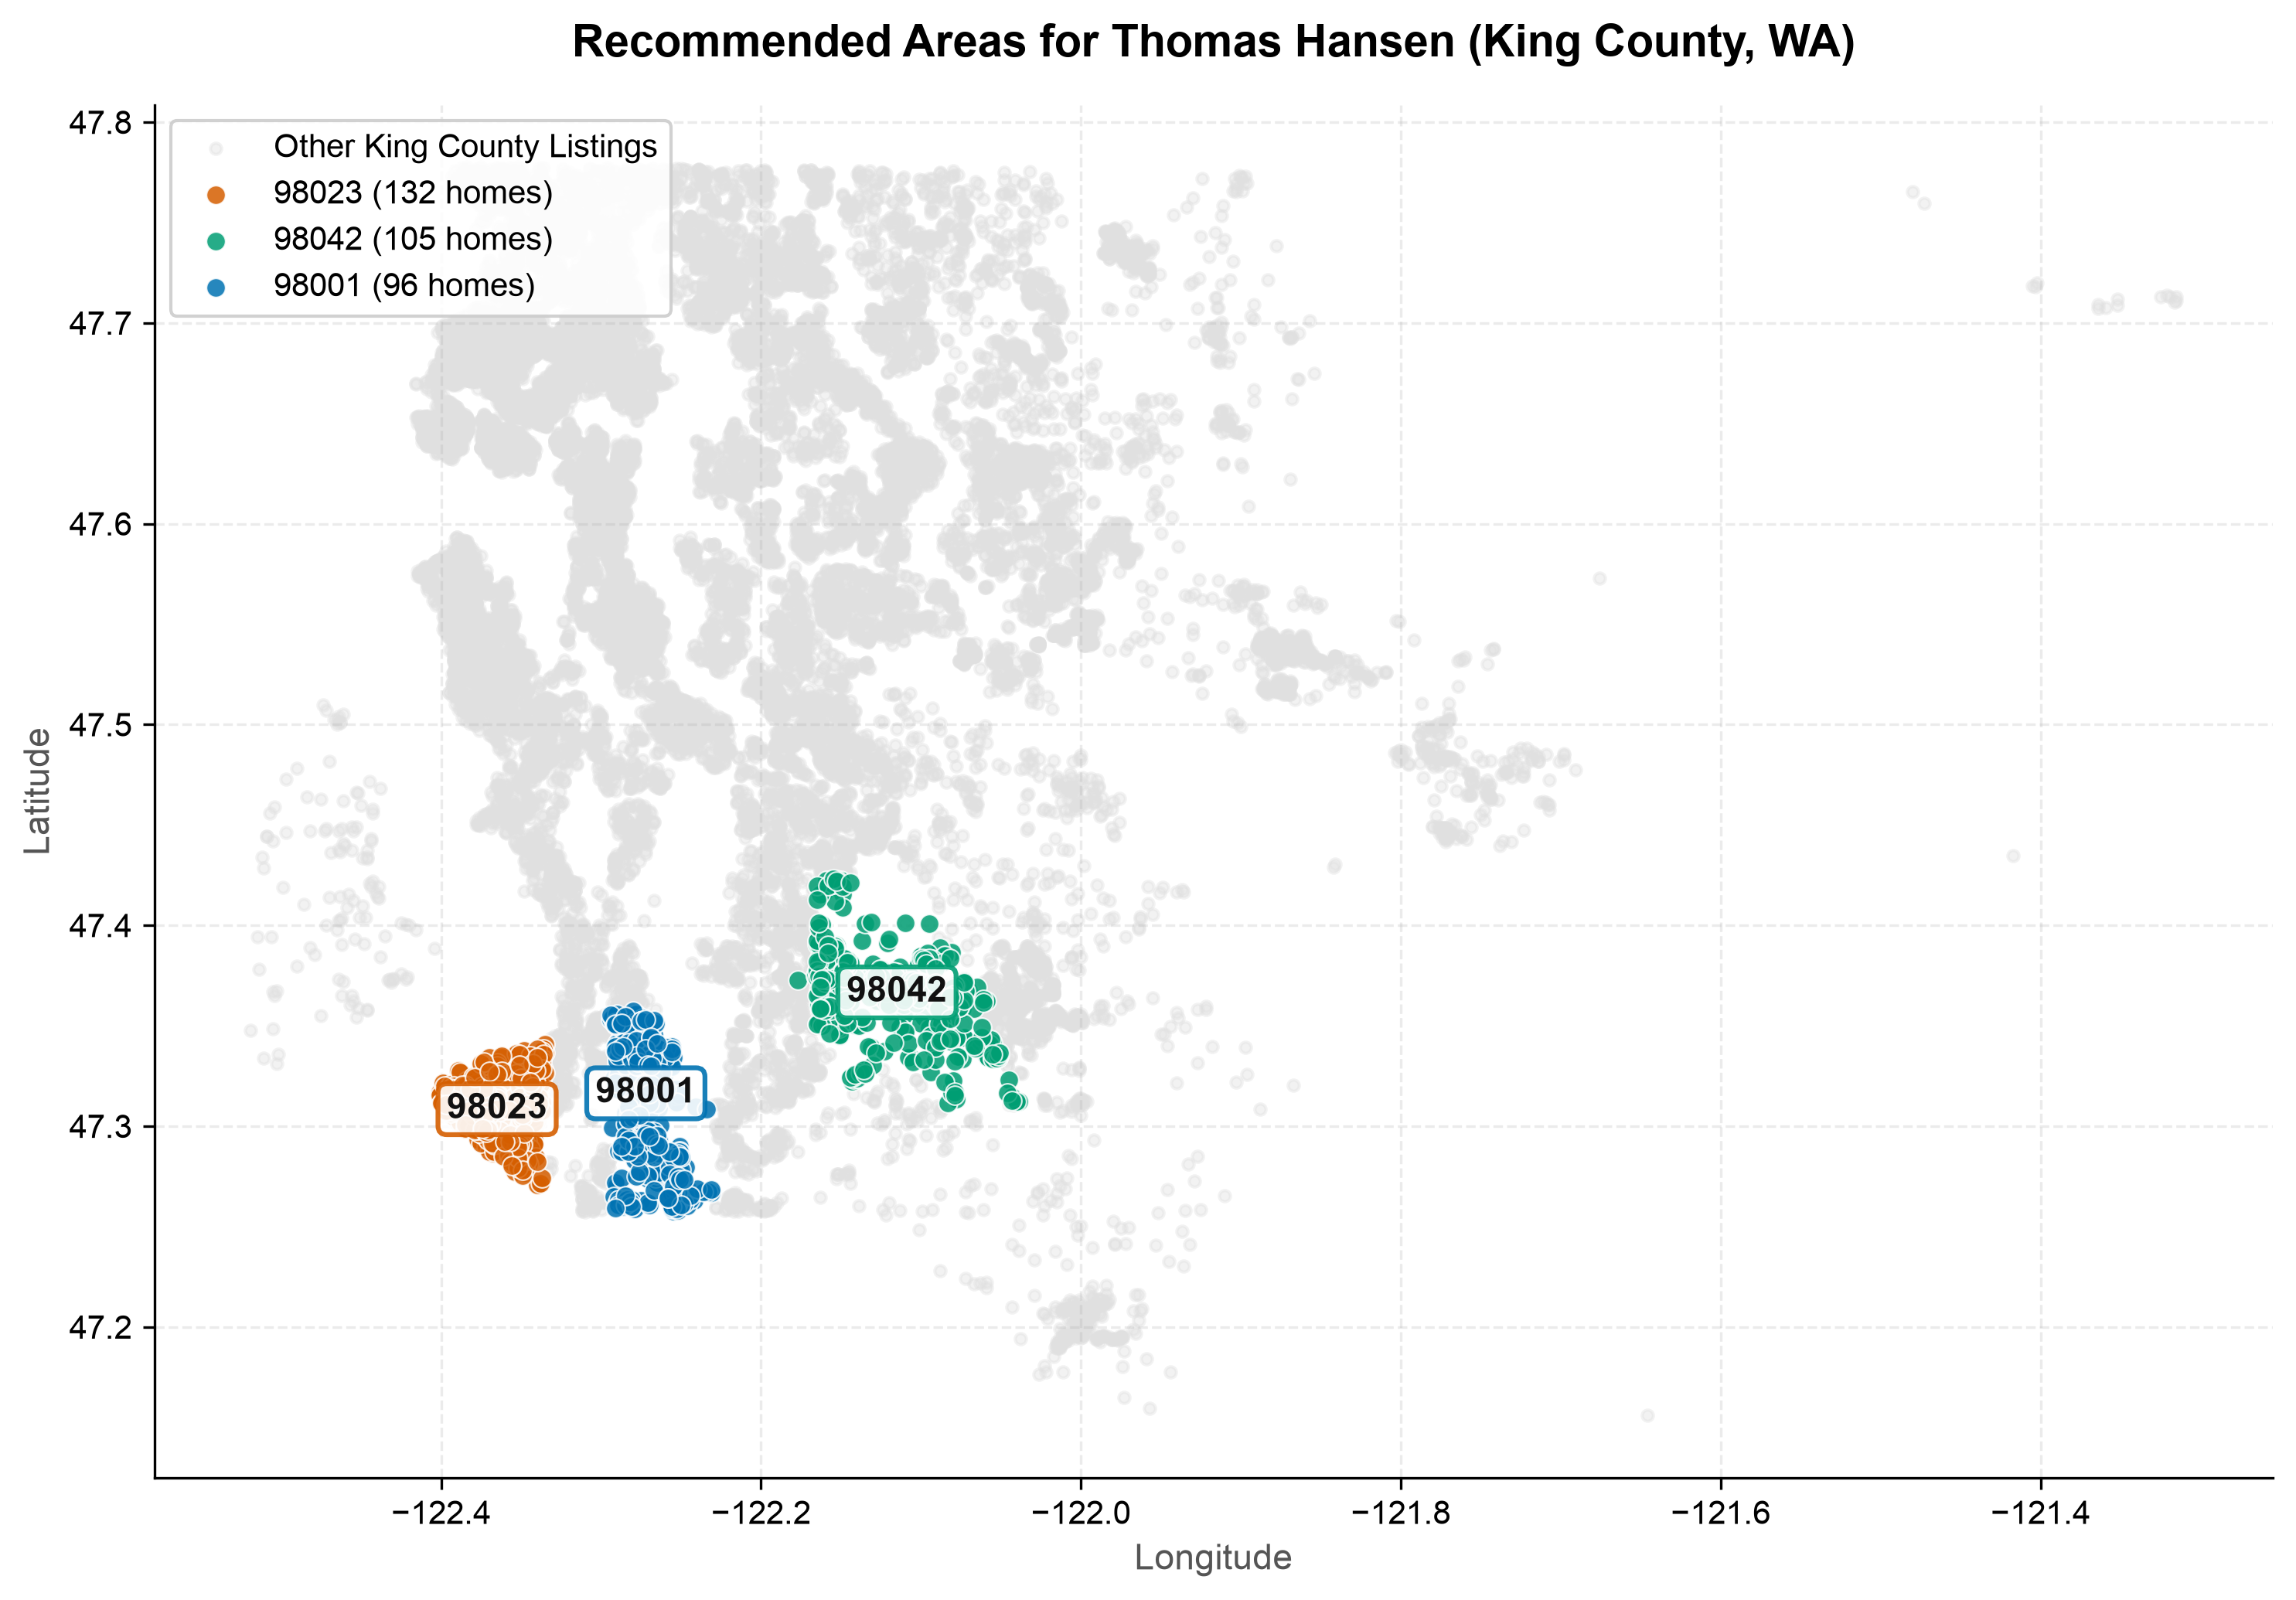

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

# Veri setini kontrol et / yükle
if 'df_unique' not in locals():
    df_house = pd.read_csv("cleandataset.csv")
    df_unique = df_house.sort_values("date").drop_duplicates(subset="id", keep="last").copy()

# Hedef 3 posta kodu ve renkleri
target_zips = {
    98023: {'name': '98023 (132 homes)', 'color': '#D55E00'}, # Kiremit / Turuncu
    98042: {'name': '98042 (105 homes)', 'color': '#009E73'}, # Yeşil
    98001: {'name': '98001 (96 homes)',  'color': '#0072B2'}  # Mavi
}

plt.rcParams["font.family"] = "Arial"
fig, ax = plt.subplots(figsize=(10, 7), dpi=300)

# 1. Tüm King County satışları (Arka plan silueti)
ax.scatter(
    df_unique['long'], 
    df_unique['lat'], 
    color='#E0E0E0', 
    s=12, 
    alpha=0.4, 
    label='Other King County Listings',
    zorder=1
)

# 2. Önerilen 3 Posta Kodu (Öne çıkan noktalar)
for zipcode, meta in target_zips.items():
    subset = df_unique[df_unique['zipcode'] == zipcode]
    ax.scatter(
        subset['long'], 
        subset['lat'], 
        color=meta['color'], 
        s=35, 
        alpha=0.85, 
        edgecolor='white', 
        linewidth=0.5,
        label=meta['name'],
        zorder=3
    )
    
    # Bölgenin merkezine etiket koy
    center_lon = subset['long'].median()
    center_lat = subset['lat'].median()
    ax.annotate(
        str(zipcode),
        (center_lon, center_lat),
        fontsize=11,
        fontweight='bold',
        color='#111111',
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=meta['color'], lw=1.5, alpha=0.9),
        ha='center',
        va='center',
        zorder=5
    )

# Başlık ve Düzenlemeler
ax.set_title("Recommended Areas for Thomas Hansen (King County, WA)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Longitude", fontsize=11, color='#555555')
ax.set_ylabel("Latitude", fontsize=11, color='#555555')

# Eksen çizgilerini sadeleştir
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.25)

# Lejant
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig("recommended_locations_map.png", dpi=300)
plt.show()